## Finding regional max values for ERA5 (CESM2 resolution)
### Values for section 4

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature
import glob
from datetime import date, timedelta
from matplotlib import rcParams

ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


In [2]:
rcParams['font.size'] = 20

#file locs
file_loc_1 = '/div/no-backup-nac/reanalysis/ERA-5/day'
land_mask_fileloc = '/div/nac/users/zofias/CESM_output/land_mask/Norway_mask_192_288_CESM2-LENS.nc'


In [3]:
#selects lat lon bounds for region for plotting
#regions = {'SA': [5,35,65,95],'EA' : [20,53,95,133],'NA' : [25,70,-150,-45], 'EU' : [35,70,-20,45],'NO' : [53,72,0,32],'NO_ext': [50,80,-30,37]}

lat_min, lat_max, lon_min, lon_max = [53,72,0,32]

In [4]:
#*****pick event date to look at*****
# E.g. Hans (2023,8,8), Nuvsvåg (2025,9,25)

selected_date = date(2023,8,8)

start_date = (selected_date - timedelta(days=5)).strftime("%Y-%m-%d")
end_date = (selected_date + timedelta(days=5)).strftime("%Y-%m-%d")
event_date = selected_date.strftime("%Y-%m-%d")

In [38]:
#read in data, select only overlap period between ERA5 adn CESM2LENS (SSP370)
era5_data_cesmres_2010_2024 = xr.open_mfdataset(f'{file_loc_1}/regridded_to_CESM2LENS/precipTOT_day_ERA5_20100101-20241231_CESMLENSgrid.nc')#.sel(valid_time=slice(start_date,end_date))
era5_data_cesmres_1940_2022 = xr.open_mfdataset(f'{file_loc_1}/regridded_to_CESM2LENS/precipTOT_day_ERA5_19400102-20221231_CESMLENSgrid.nc')#.sel(valid_time=slice(start_date,end_date))

era5_data_cesmres_2010_2024 = era5_data_cesmres_2010_2024.rename({'valid_time':'time'})

era5_data_cesmres = xr.concat([era5_data_cesmres_1940_2022['tp'], era5_data_cesmres_2010_2024['tp']], dim='time').to_dataset(name='tp')

#land mask
land_percent_data = xr.open_dataset(land_mask_fileloc)
land_percent_data = land_percent_data.assign_coords(lon=(((land_percent_data.lon + 180) % 360) - 180)).sortby('lon')
land_mask = land_percent_data.mask

In [39]:
#units are in m (daily), convert to mm/day
era5_data_cesmres['tp'] = era5_data_cesmres['tp'] * 1000
era5_data_cesmres["tp"] = era5_data_cesmres.tp.assign_attrs(long_name = "Total precipitation", units='mm/day',cell_methods = "time: sum")

era5_data_cesmres['PRECT_land'] = era5_data_cesmres['tp'].where(land_mask)


#era5_data_origres['tp'] = era5_data_origres['tp'] * 1000
#era5_data_origres["tp"] = era5_data_origres.tp.assign_attrs(long_name = "Total precipitation", units='mm/day',cell_methods = "time: sum")

/div/qbo/users/py3Env/venv_basic/lib/python3.8/site-packages/xarray/core/indexing.py:1374: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]
/div/qbo/users/py3Env/venv_basic/lib/python3.8/site-packages/xarray/core/indexing.py:1374: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]


In [40]:
#calculate 5 day sum
era5_data_cesmres['rx5day'] = era5_data_cesmres['PRECT_land'].rolling(time=5,min_periods=5,center=True).sum(skipna=True)
era5_data_cesmres['rx5day_max'] = era5_data_cesmres['rx5day'].max(dim='time')

In [41]:
era5_data_cesmres

<xarray.Dataset>
Dimensions:     (time: 35794, lon: 288, lat: 192)
Coordinates:
  * time        (time) datetime64[ns] 1940-01-02T11:00:00 ... 2024-12-31
  * lon         (lon) float64 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
  * lat         (lat) float64 -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
Data variables:
    tp          (time, lat, lon) float32 dask.array<chunksize=(30315, 192, 288), meta=np.ndarray>
    PRECT_land  (time, lat, lon) float32 dask.array<chunksize=(30315, 192, 288), meta=np.ndarray>
    rx5day      (time, lat, lon) float32 dask.array<chunksize=(30317, 192, 288), meta=np.ndarray>
    rx5day_max  (lat, lon) float32 dask.array<chunksize=(192, 288), meta=np.ndarray>

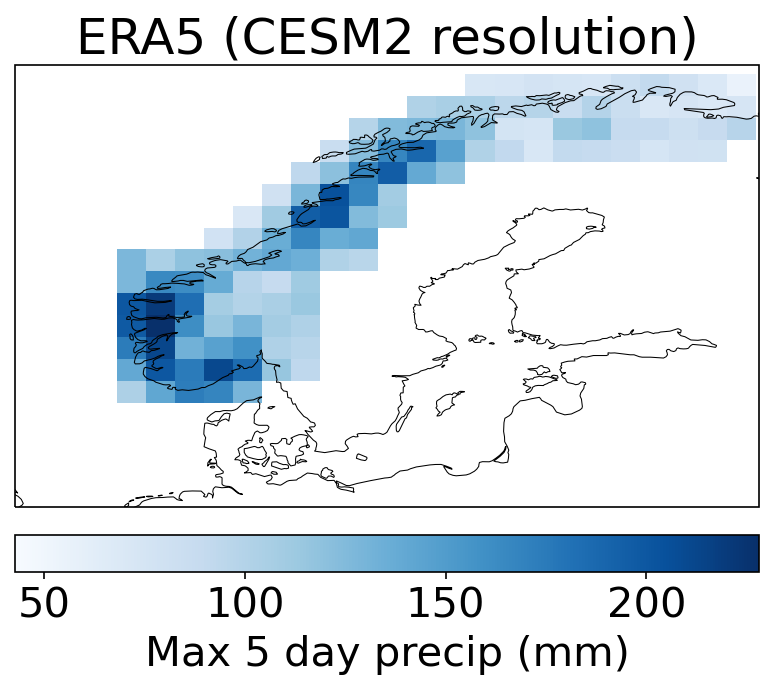

In [42]:
#Plot event on CESM2 resolution
fig, axis = plt.subplots(1, 1, dpi=150, subplot_kw=dict(projection=ccrs.PlateCarree()))
fg = era5_data_cesmres['rx5day_max'].plot(cmap='Blues',
                                                       #vmax=200,
    cbar_kwargs={'label': f'Max 5 day precip (mm)','orientation':'horizontal','pad':0.05},
    xlim=(lon_min,lon_max),
    ylim=(lat_min,lat_max),
    )

plt.title(f"ERA5 (CESM2 resolution)")
axis.coastlines(linewidth=0.5)  # cartopy function
#axis.add_feature(cartopy.feature.OCEAN,facecolor=("aliceblue"))

In [69]:
#maximum precip value for West Norway
print(era5_data_cesmres['PRECT_land'].sel(lat=slice(58,64), lon=slice(4,8)).max().values)
print(era5_data_cesmres['rx5day_max'].sel(lat=slice(58,64), lon=slice(4,8)).max().values)

106.563416
228.01666


In [70]:
#maximum precip value for Trondelag
print(era5_data_cesmres['PRECT_land'].sel(lat=slice(62,65), lon=slice(8,14.4)).max().values)
print(era5_data_cesmres['rx5day_max'].sel(lat=slice(62,65), lon=slice(8,14.4)).max().values)

62.468266
167.0816


In [71]:
#maximum precip value for Northern Norway 
print(era5_data_cesmres['PRECT_land'].sel(lat=slice(65,71), lon=slice(8,32)).max().values)
print(era5_data_cesmres['rx5day_max'].sel(lat=slice(65,71), lon=slice(8,32)).max().values)

80.53066
204.28891


In [72]:
#maximum precip value for Eastern Norway 
print(era5_data_cesmres['PRECT_land'].sel(lat=slice(58,62), lon=slice(8,13)).max().values)
print(era5_data_cesmres['rx5day_max'].sel(lat=slice(58,62), lon=slice(8,13)).max().values)

67.3222
210.79486


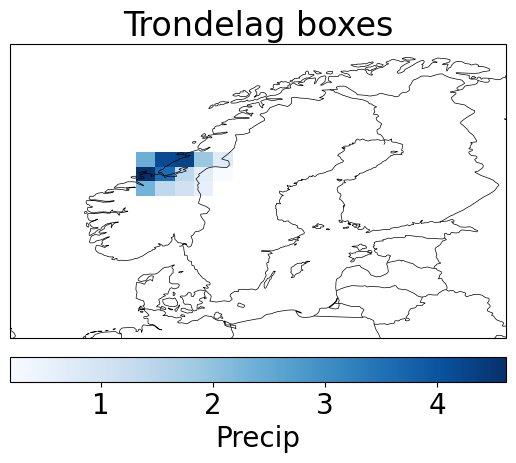

In [61]:
#Plot event on CESM2 resolution
fig, axis = plt.subplots(1, 1, dpi=100, subplot_kw=dict(projection=ccrs.PlateCarree()))
fg = era5_data_cesmres['PRECT_land'].isel(time=-1).sel(lat=slice(62,65), lon=slice(8,14.4)).plot(cmap='Blues',
                                                       #vmax=200,
    cbar_kwargs={'label': f'Precip','orientation':'horizontal','pad':0.05},
    xlim=(lon_min,lon_max),
    ylim=(lat_min,lat_max),
    )

plt.title(f"Trondelag boxes")
axis.coastlines(linewidth=0.5)  # cartopy function
axis.add_feature(cartopy.feature.BORDERS,linewidth=0.5)

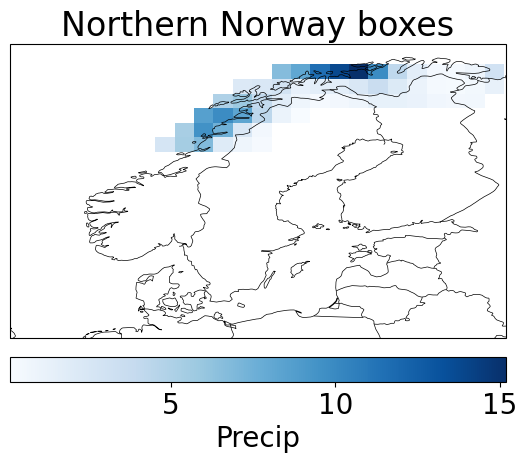

In [62]:
#Plot event on CESM2 resolution
fig, axis = plt.subplots(1, 1, dpi=100, subplot_kw=dict(projection=ccrs.PlateCarree()))
fg = era5_data_cesmres['PRECT_land'].isel(time=-1).sel(lat=slice(65,71), lon=slice(8,32)).plot(cmap='Blues',
                                                       #vmax=200,
    cbar_kwargs={'label': f'Precip','orientation':'horizontal','pad':0.05},
    xlim=(lon_min,lon_max),
    ylim=(lat_min,lat_max),
    )

plt.title(f"Northern Norway boxes")
axis.coastlines(linewidth=0.5)  # cartopy function
axis.add_feature(cartopy.feature.BORDERS,linewidth=0.5)

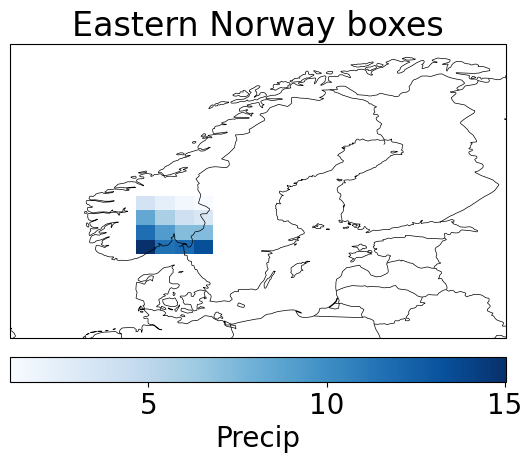

In [63]:
#Plot event on CESM2 resolution
fig, axis = plt.subplots(1, 1, dpi=100, subplot_kw=dict(projection=ccrs.PlateCarree()))
fg = era5_data_cesmres['PRECT_land'].isel(time=-1).sel(lat=slice(58,62), lon=slice(8,13)).plot(cmap='Blues',
                                                       #vmax=200,
    cbar_kwargs={'label': f'Precip','orientation':'horizontal','pad':0.05},
    xlim=(lon_min,lon_max),
    ylim=(lat_min,lat_max),
    )

plt.title(f"Eastern Norway boxes")
axis.coastlines(linewidth=0.5)  # cartopy function
axis.add_feature(cartopy.feature.BORDERS,linewidth=0.5)

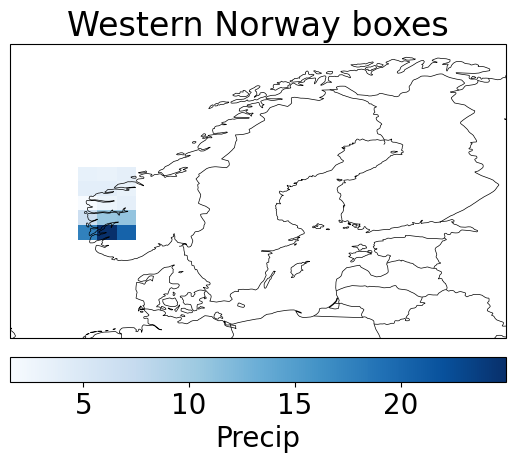

In [73]:
#Plot event on CESM2 resolution
fig, axis = plt.subplots(1, 1, dpi=100, subplot_kw=dict(projection=ccrs.PlateCarree()))
fg = era5_data_cesmres['PRECT_land'].isel(time=-1).sel(lat=slice(59,64), lon=slice(4,8)).plot(cmap='Blues',
                                                       #vmax=200,
    cbar_kwargs={'label': f'Precip','orientation':'horizontal','pad':0.05},
    xlim=(lon_min,lon_max),
    ylim=(lat_min,lat_max),
    )

plt.title(f"Western Norway boxes")
axis.coastlines(linewidth=0.5)  # cartopy function
axis.add_feature(cartopy.feature.BORDERS,linewidth=0.5)